# Stochastic Gradient Descent (SGD)

In the previous chapter, we trained a Neural Network with Gradient Descent on a small dataset of $N = 1000$ points in $\mathbb{R}^2$. In realistic applications, however, datasets are **huge**: the classical MNIST dataset of handwritten digits contains $N = 60\,000$ images in $\mathbb{R}^{784}$, ImageNet contains more than $10^6$ images in $\mathbb{R}^{150\,528}$, while modern Large Language Models are trained on datasets containing trillions of words. In these scenarios, even a **single** iteration of Gradient Descent is extremely expensive. In this chapter, we introduce the algorithm that made the training of large models possible: **Stochastic Gradient Descent (SGD)**.

## The structure of the loss function

When training a Machine Learning model, we typically deal with a dataset

$$
(X, Y) = \{ (x^{(i)}, y^{(i)}) \}_{i=1}^N,
$$

and a **parametric model** $ f_\Theta(x) $ whose parameters $\Theta$ (also called **weights**) must be learned. As we already discussed, the loss function used for training has a very particular structure: it is the **average of $N$ independent terms**, one for each datapoint:

$$
\mathcal{L}(\Theta; X, Y) = \frac{1}{N} \sum_{i=1}^N \ell_i(\Theta), \qquad \ell_i(\Theta) := \ell(\Theta; x^{(i)}, y^{(i)}),
$$

where $\ell_i$ quantifies the error on the $i$-th training sample (for our Neural Network classifier, $\ell_i$ is the Cross-Entropy between the predicted probabilities $\hat{y}^{(i)}$ and the one-hot label $y^{(i)}$). Optimization problems of this form are known as **Empirical Risk Minimization (ERM)** problems, or *finite-sum* problems.

The **Gradient Descent (GD)** method (from the previous chapter) updates the parameters iteratively as:

$$
\Theta^{(k+1)} = \Theta^{(k)} - \eta_k \, \nabla_\Theta \mathcal{L}(\Theta^{(k)}; X, Y)
= \Theta^{(k)} - \eta_k \, \frac{1}{N}\sum_{i=1}^N \nabla_\Theta \ell_i(\Theta^{(k)}),
$$

where, following the Machine Learning notation, $\eta_k > 0$ denotes the **learning rate** (what we called step size $\alpha_k$ in the previous chapter).

## Motivation for Stochastic Gradient Descent

While the computation of each $\nabla_\Theta \ell_i(\Theta)$ is inexpensive (it requires one forward and one backward pass on a single datapoint), the full gradient $\nabla_\Theta \mathcal{L}(\Theta; X, Y)$ requires to compute **all the $N$ terms** of the sum, which is a prohibitive cost when $N$ is very large. Moreover, all the datapoints have to be processed *before* making a single update of the parameters: if the dataset contains $10^6$ images, we need to process $10^6$ images just to make a single (small) step toward the minimum.

But do we really need the **exact** gradient? Remember that GD converges for any (small enough) step size: we are not interested in following *exactly* the direction of steepest descent, we just need a direction which, *on average*, decreases the loss. Moreover, datasets are usually highly **redundant**: think of $60\,000$ images of handwritten digits, where thousands of images represent very similar "$1$"s. The gradient computed on a few hundreds of images will be very similar to the gradient computed on the whole dataset.

The **Stochastic Gradient Descent (SGD)** algorithm is based exactly on this idea: replacing the **exact gradient** with a **stochastic approximation**, computed on a small random subset of the data (a *mini-batch*).

## The stochastic gradient

Let $N_\text{batch} \ll N$ be the **batch size**, and let $\mathcal{M} \subset \{1,\dots,N\}$ be a random subset of indices such that $|\mathcal{M}| = N_\text{batch}$. We define the **stochastic gradient** as the average of the gradients of the datapoints in $\mathcal{M}$:

$$
\nabla_\Theta \mathcal{L}(\Theta; \mathcal{M}) := \frac{1}{N_\text{batch}}\sum_{i\in\mathcal{M}} \nabla_\Theta \ell_i(\Theta).
$$

Note that computing $\nabla_\Theta \mathcal{L}(\Theta; \mathcal{M})$ costs $N_\text{batch}$ forward and backward passes, instead of $N$. Of course, $\nabla_\Theta \mathcal{L}(\Theta; \mathcal{M})$ is a **random variable**, since it depends on the random choice of $\mathcal{M}$. Its two key properties are the following.

**1. It is unbiased.** Consider first the case $N_\text{batch} = 1$, i.e. $\mathcal{M} = \{ i \}$, where $i$ is sampled uniformly from $\{ 1, \dots, N \}$. Then

$$
\mathbb{E}_i \left[ \nabla_\Theta \ell_i(\Theta) \right] = \sum_{j=1}^N \mathbb{P}(i = j) \nabla_\Theta \ell_j(\Theta) = \frac{1}{N} \sum_{j=1}^N \nabla_\Theta \ell_j(\Theta) = \nabla_\Theta \mathcal{L}(\Theta; X, Y).
$$

By linearity of the expectation, the same holds for any batch size, as each element of $\mathcal{M}$ is (marginally) uniformly distributed on $\{1, \dots, N\}$:

$$
\mathbb{E}_\mathcal{M} \left[ \nabla_\Theta \mathcal{L}(\Theta; \mathcal{M}) \right] = \nabla_\Theta \mathcal{L}(\Theta; X, Y).
$$

In other words, the stochastic gradient is **on average** equal to the true gradient: it is an *unbiased estimator* of $\nabla_\Theta \mathcal{L}$.

**2. Its variance decreases with the batch size.** If the indices in $\mathcal{M}$ are sampled independently (i.e. with replacement), the stochastic gradient is the average of $N_\text{batch}$ i.i.d. random vectors, each with variance

$$
\sigma^2(\Theta) := \mathbb{E}_i \left[ \| \nabla_\Theta \ell_i(\Theta) - \nabla_\Theta \mathcal{L}(\Theta; X, Y) \|_2^2 \right],
$$

and therefore

$$
\mathbb{E}_\mathcal{M} \left[ \| \nabla_\Theta \mathcal{L}(\Theta; \mathcal{M}) - \nabla_\Theta \mathcal{L}(\Theta; X, Y) \|_2^2 \right] = \frac{\sigma^2(\Theta)}{N_\text{batch}}.
$$

Thus, the batch size controls a **trade-off**: small batches give cheap but noisy gradients, while large batches give accurate but expensive gradients. In the limit case $N_\text{batch} = N$, we recover the exact gradient (and GD).

## The SGD Algorithm

The idea of SGD is to replace the true gradient with the stochastic gradient in the GD iteration:

$$
\Theta^{(k+1)} = \Theta^{(k)} - \eta_k \, \nabla_\Theta \mathcal{L}(\Theta^{(k)}; \mathcal{M}_k),
$$

where $\mathcal{M}_k$ is a different random mini-batch at each iteration. In practice, instead of sampling a new random batch independently at each iteration, the dataset is **shuffled** and then **partitioned** into $\lceil N / N_\text{batch} \rceil$ disjoint batches $\mathcal{M}_1, \mathcal{M}_2, \dots$, which are processed one after the other. This guarantees that each datapoint is used exactly once every $\lceil N / N_\text{batch} \rceil$ iterations.

![](./fig/SGD.png)

When the entire dataset has been processed (i.e. after $\lceil N / N_\text{batch} \rceil$ iterations), we say one **epoch** of SGD has been completed. The dataset is then shuffled again, and a new epoch begins. Summing up, the algorithm reads:

**Input**: initial parameters $\Theta^{(0)}$, learning rates $\{ \eta_k \}_k$, batch size $N_\text{batch}$, number of epochs $E$.
**For** each epoch $e = 1, \dots, E$:
1. **Shuffle** the dataset, and split it into $n_\text{batches} = \lceil N / N_\text{batch} \rceil$ batches $\mathcal{M}_1, \dots, \mathcal{M}_{n_\text{batches}}$.
2. **For** each batch $\mathcal{M}_j$, $j = 1, \dots, n_\text{batches}$:
   - compute the stochastic gradient $g^{(k)} = \nabla_\Theta \mathcal{L}(\Theta^{(k)}; \mathcal{M}_j)$ (forward + backward pass on the batch),
   - update the parameters: $\Theta^{(k+1)} = \Theta^{(k)} - \eta_k \, g^{(k)}$,
   - $k \leftarrow k + 1$.

```{important}
Make sure you understand the difference between the following terms, which are ubiquitous in Deep Learning:
- **Batch** (or *mini-batch*): the subset $\mathcal{M}_k$ of datapoints used to compute one stochastic gradient. Its size $N_\text{batch}$ is the **batch size**.
- **Iteration** (or *step*): a single update of the parameters, which processes one batch.
- **Epoch**: a full pass over the dataset, consisting of $\lceil N / N_\text{batch} \rceil$ iterations.

For example, training for $E = 10$ epochs on a dataset with $N = 60\,000$ datapoints and batch size $N_\text{batch} = 100$ means performing $10 \cdot 600 = 6\,000$ iterations. On the same dataset, $10$ epochs of GD correspond to only $10$ iterations. **Both algorithms have the same computational cost**, since both of them process each datapoint $10$ times!
```

Depending on the batch size, we distinguish:
- $N_\text{batch} = 1$: **pure** (or *online*) SGD. The cheapest and noisiest version. It does not exploit the parallelism of modern hardware (matrix-matrix products on a batch are much more efficient than many matrix-vector products).
- $N_\text{batch} = N$: (full-batch) **GD**.
- $1 < N_\text{batch} < N$: **mini-batch SGD**, the standard choice in practice. Typical values are $N_\text{batch} \in \{ 16, 32, 64, 128, 256 \}$, mostly limited by the memory of the GPU.

## Comparison with Full Gradient Descent

| Property | Gradient Descent (GD) | Stochastic Gradient Descent (SGD) |
|-----------|------------------------|------------------------------------|
| Gradient computation | Full dataset | Random subset (mini-batch) |
| Iteration cost | High (depends on $N$) | Low (depends on $N_\text{batch}$) |
| Iterations per epoch | $1$ | $\lceil N / N_\text{batch} \rceil$ |
| Gradient | Exact (deterministic) | Approximated (stochastic) |
| Convergence | Smooth and stable | Noisy, but much faster per epoch |
| Scalability | Poor for large datasets | Excellent |

## Convergence of SGD and the learning rate

Since the stochastic gradient is only an approximation of the true gradient, SGD does **not** decrease the loss at every iteration: the loss curve of SGD is typically noisy. But what happens in the limit?

Assume we are close to a minimum $\Theta^*$. Here the true gradient is (almost) zero, but the stochastic gradient is not, since its variance $\sigma^2(\Theta^*) / N_\text{batch}$ is in general positive (each datapoint "pulls" the parameters toward its own minimum). Therefore, with a **constant** learning rate $\eta$, the iterates of SGD never settle down: they keep bouncing in a neighborhood of $\Theta^*$, whose size is proportional to $\eta \, \sigma^2 / N_\text{batch}$.

To obtain convergence, the learning rate must go to zero. Indeed, it can be proved that (under suitable assumptions on $\mathcal{L}$) SGD converges to a stationary point if the learning rates satisfy the so-called **Robbins-Monro conditions**:

$$
\sum_{k=0}^\infty \eta_k = \infty, \qquad \sum_{k=0}^\infty \eta_k^2 < \infty.
$$

The first condition guarantees that the iterates can travel arbitrarily far (so that they can reach the minimum from any initial point), while the second guarantees that the noise is eventually averaged out. A typical example is $\eta_k = \frac{\eta_0}{1 + \gamma k}$, with $\gamma > 0$.

In practice, common choices are:
- **Constant** learning rate: $\eta_k = \eta$. Simple, and often good enough.
- **Step decay**: the learning rate is divided by a factor (e.g. $10$) after a fixed number of epochs.
- **Inverse decay**: $\eta_k = \frac{\eta_0}{1 + \gamma k}$.
- **Cosine decay**: $\eta_k = \frac{\eta_0}{2} \left( 1 + \cos\left( \frac{\pi k}{K} \right) \right)$, where $K$ is the total number of iterations. This is very popular in modern Deep Learning.

```{warning}
SGD has some drawbacks compared to GD. In particular, there is no way to check whether it reached convergence: we cannot compute $\|\nabla_\Theta \mathcal{L}(\Theta; X, Y)\|_2$ (that would require a pass over the whole dataset), and the norm of the stochastic gradient does not go to zero. For the same reason, we cannot use backtracking. As a consequence, the algorithm is usually stopped **only after a fixed number of epochs** (or when the loss on a validation set stops improving, a technique known as **early stopping**), and the learning rate must be set **by hand**. These problems are partially solved by modern algorithms such as Adam, which we will discuss in the next chapter.
```

```{note}
**Why does SGD work so well for Neural Networks?** Besides the computational advantage, it has been observed that the **noise** of SGD is actually beneficial for training Neural Networks: it helps the iterates to escape from saddle points and from *sharp* minima, which are known to generalize worse than *flat* minima. This is one of the reasons why SGD (and its variants) is still the standard algorithm for training Neural Networks, even when the full gradient would be computationally affordable.
```

## Implementation

We now implement SGD for the training of our MLP classifier. As in the previous chapter, we first copy the code for the MLP (expand the cell below to see it).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ---- Code from the previous chapters ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

def accuracy(Y_hat, y):
    return np.mean(Y_hat.argmax(axis=1) == y)

The implementation of SGD follows exactly the algorithm described above. Note that, since our `backward` function computes the gradient of the **average** loss over the datapoints it receives, calling it on a batch directly returns the stochastic gradient $\nabla_\Theta \mathcal{L}(\Theta; \mathcal{M}_k)$. At the end of each epoch, we evaluate the loss and the accuracy on the whole training set, to monitor the training.

In [2]:
def train_sgd(params, X, Y, y, lr=1e-2, batch_size=32, epochs=10, seed=0):
    """
    Trains the MLP with mini-batch SGD.
    params: list of [W, b]. The initial parameters (modified in-place).
    X, Y, y: the dataset (inputs, one-hot labels, integer labels).
    lr: the learning rate. Either a float, or a function k -> eta_k.
    """
    rng = np.random.default_rng(seed)
    N = X.shape[0]
    k = 0
    loss_hist, acc_hist, time_hist = [], [], []
    start = time.time()

    for epoch in range(epochs):
        # Shuffle the dataset
        idx = rng.permutation(N)

        for start_batch in range(0, N, batch_size):
            # Select the batch M_k
            batch_idx = idx[start_batch:start_batch + batch_size]
            Xb, Yb = X[batch_idx], Y[batch_idx]

            # Stochastic gradient (forward + backward pass on the batch)
            Y_hat, cache = forward(params, Xb)
            grads = backward(params, cache, Yb)

            # SGD update
            eta = lr(k) if callable(lr) else lr
            for (W, b), (dW, db) in zip(params, grads):
                W -= eta * dW
                b -= eta * db
            k += 1

        # Log full-dataset metrics after each epoch
        Y_hat, _ = forward(params, X)
        loss_hist.append(cross_entropy(Y_hat, Y))
        acc_hist.append(accuracy(Y_hat, y))
        time_hist.append(time.time() - start)

    return params, np.array(loss_hist), np.array(acc_hist), np.array(time_hist)

## Experiments

### The dataset

To test SGD, we consider a more challenging classification problem: the **spiral dataset**, a synthetic dataset with $K = 3$ classes, where the points of each class lie on an arm of a spiral. We generate $N = 30\,000$ datapoints, i.e. $30$ times more than the triangle dataset of the previous chapter.

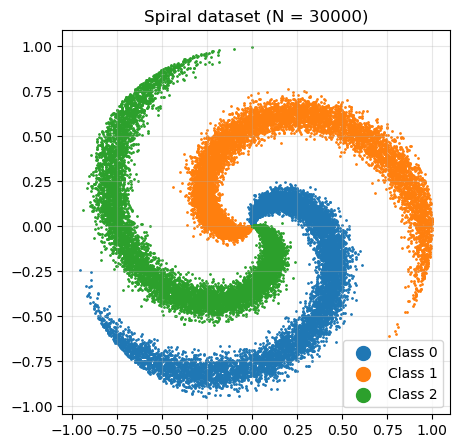

In [3]:
def make_spirals(N, K=3, noise=0.2, seed=0):
    """
    Generates N points in R^2 on K intertwined spirals (one per class).
    """
    rng = np.random.default_rng(seed)
    n = N // K
    X = np.zeros((n * K, 2))
    y = np.zeros(n * K, dtype=int)
    for k in range(K):
        r = np.linspace(0.0, 1, n)                                        # radius
        t = np.linspace(k * 4, (k + 1) * 4, n) + noise * rng.normal(size=n)  # angle
        X[k * n:(k + 1) * n] = np.stack([r * np.sin(t), r * np.cos(t)], axis=1)
        y[k * n:(k + 1) * n] = k
    return X, y

X, y = make_spirals(30000)
Y = np.eye(3)[y]
N = X.shape[0]

plt.figure(figsize=(5, 5))
for k in range(3):
    plt.scatter(X[y == k, 0], X[y == k, 1], s=1, label=f"Class {k}")
plt.legend(markerscale=10)
plt.gca().set_aspect("equal")
plt.title(f"Spiral dataset (N = {N})")
plt.grid(alpha=0.3)
plt.show()

### Variance of the stochastic gradient

First, let's verify numerically that the stochastic gradient is an unbiased estimator of the true gradient, and that its variance decreases as $1 / N_\text{batch}$. To do that, we fix the parameters $\Theta$ (at initialization) and we compute the stochastic gradient over many random batches of the same size.

N_batch =     1: relative error of the average stochastic gradient = 0.272
N_batch =     4: relative error of the average stochastic gradient = 0.099
N_batch =    16: relative error of the average stochastic gradient = 0.026
N_batch =    64: relative error of the average stochastic gradient = 0.015
N_batch =   256: relative error of the average stochastic gradient = 0.016
N_batch =  1024: relative error of the average stochastic gradient = 0.006


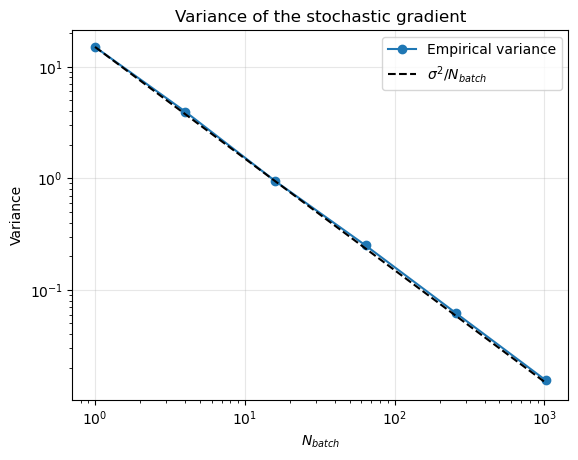

In [4]:
def flatten(grads):
    """Concatenates all the gradients in a single vector."""
    return np.concatenate([g.ravel() for layer in grads for g in layer])

params = init_params([2, 64, 64, 3], seed=0)

# True gradient (on the whole dataset)
Y_hat, cache = forward(params, X)
true_grad = flatten(backward(params, cache, Y))

rng = np.random.default_rng(0)
batch_sizes = [1, 4, 16, 64, 256, 1024]
mean_err, variances = [], []
for bs in batch_sizes:
    sg = []
    for _ in range(300):
        batch_idx = rng.choice(N, bs, replace=True)
        Y_hat, cache = forward(params, X[batch_idx])
        sg.append(flatten(backward(params, cache, Y[batch_idx])))
    sg = np.array(sg)
    mean_err.append(np.linalg.norm(sg.mean(axis=0) - true_grad) / np.linalg.norm(true_grad))
    variances.append(np.mean(np.sum((sg - true_grad)**2, axis=1)))

for bs, e in zip(batch_sizes, mean_err):
    print(f"N_batch = {bs:5d}: relative error of the average stochastic gradient = {e:.3f}")

plt.loglog(batch_sizes, variances, 'o-', label="Empirical variance")
plt.loglog(batch_sizes, variances[0] / np.array(batch_sizes), 'k--', label=r"$\sigma^2 / N_{batch}$")
plt.xlabel(r"$N_{batch}$")
plt.ylabel("Variance")
plt.title("Variance of the stochastic gradient")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The average of the stochastic gradients is close to the true gradient (the residual error is due to the finite number of samples, and it gets smaller for larger batch sizes), and the variance perfectly follows the theoretical $1 / N_\text{batch}$ behavior.

### GD vs. SGD

We now train the same MLP, with two hidden layers of $64$ neurons, with GD (i.e. $N_\text{batch} = N$) and with SGD for different batch sizes, for the **same number of epochs** (i.e. with the same computational cost). The learning rates have been chosen (by trial and error) to work well for each batch size.

In [5]:
epochs = 30
configs = [(N, 0.5), (256, 0.1), (64, 0.1), (16, 0.05)]  # (batch size, learning rate)
results = {}

for bs, lr in configs:
    params = init_params([2, 64, 64, 3], seed=0)
    params, loss_hist, acc_hist, time_hist = train_sgd(params, X, Y, y, lr=lr,
                                                       batch_size=bs, epochs=epochs)
    name = "GD" if bs == N else f"SGD ($N_{{batch}}$ = {bs})"
    results[name] = (params, loss_hist, acc_hist, time_hist)
    print(f"{name:25s}: iterations = {epochs * int(np.ceil(N / bs)):6d}, final loss = {loss_hist[-1]:.4f}, "
          f"final accuracy = {acc_hist[-1]*100:.2f}%, time = {time_hist[-1]:.2f}s")

GD                       : iterations =     30, final loss = 0.3764, final accuracy = 92.53%, time = 1.68s
SGD ($N_{batch}$ = 256)  : iterations =   3540, final loss = 0.0239, final accuracy = 99.59%, time = 1.99s
SGD ($N_{batch}$ = 64)   : iterations =  14070, final loss = 0.0109, final accuracy = 99.68%, time = 2.37s
SGD ($N_{batch}$ = 16)   : iterations =  56250, final loss = 0.0095, final accuracy = 99.68%, time = 4.26s


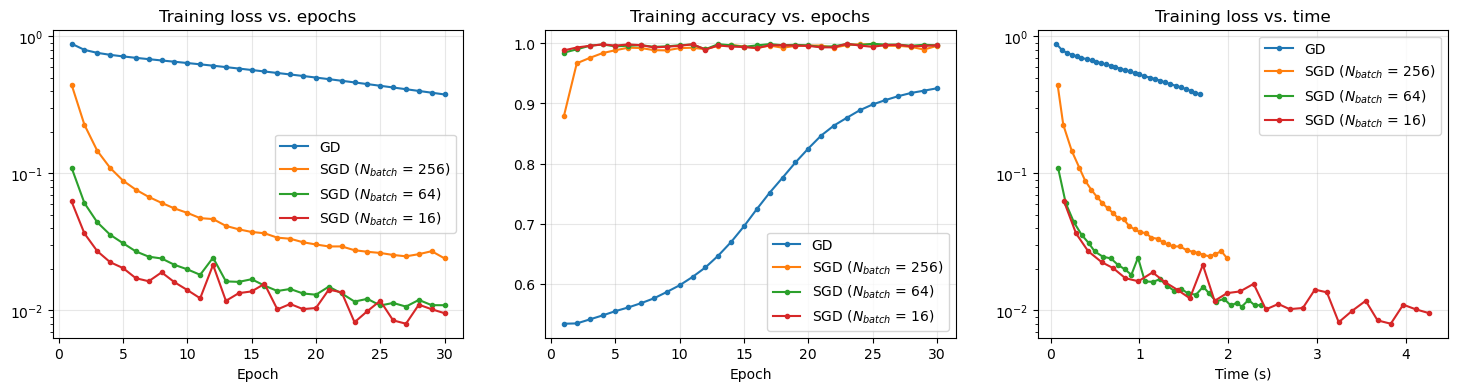

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, (_, loss_hist, acc_hist, time_hist) in results.items():
    axes[0].semilogy(np.arange(1, epochs + 1), loss_hist, 'o-', ms=3, label=name)
    axes[1].plot(np.arange(1, epochs + 1), acc_hist, 'o-', ms=3, label=name)
    axes[2].semilogy(time_hist, loss_hist, 'o-', ms=3, label=name)

axes[0].set_title("Training loss vs. epochs")
axes[0].set_xlabel("Epoch")
axes[1].set_title("Training accuracy vs. epochs")
axes[1].set_xlabel("Epoch")
axes[2].set_title("Training loss vs. time")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

The results are impressive: with the same computational cost (same number of epochs), SGD reaches a much lower loss than GD. Indeed, in $30$ epochs, GD performed only $30$ updates of the parameters, while SGD with $N_\text{batch} = 64$ performed almost $15\,000$ updates, each of them computed on an approximated (but good enough) gradient. Note, however, that smaller batch sizes are not always better in terms of time: with very small batches, the number of iterations per epoch grows, and we lose the efficiency of matrix-matrix products (in our case, the overhead of the Python `for` loop also plays a role).

Let's visualize the decision regions learned by GD and by SGD.

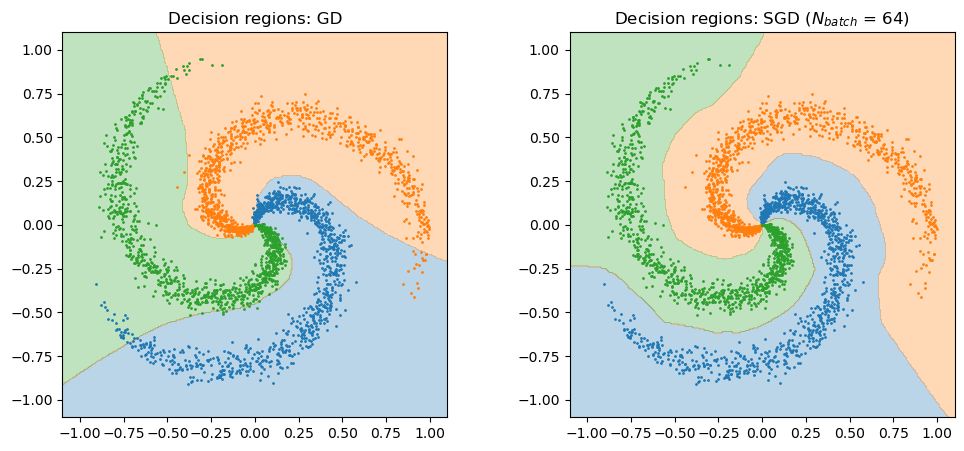

In [7]:
xx1, xx2 = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["GD", "SGD ($N_{batch}$ = 64)"]):
    params = results[name][0]
    P_grid, _ = forward(params, grid)
    ax.contourf(xx1, xx2, P_grid.argmax(axis=1).reshape(xx1.shape), levels=[-0.5, 0.5, 1.5, 2.5],
                colors=["tab:blue", "tab:orange", "tab:green"], alpha=0.3)
    for k in range(3):
        ax.scatter(X[y == k, 0][::10], X[y == k, 1][::10], s=1)
    ax.set_title(f"Decision regions: {name}")
    ax.set_aspect("equal")
plt.show()

### The effect of the learning rate schedule

Finally, let's look more closely at the behavior of SGD with constant learning rate. Since the loss we plotted above is evaluated only at the end of each epoch, it hides the noise of SGD. Let's train the network with $N_\text{batch} = 16$ for $20$ epochs, with a large constant learning rate and with a decaying learning rate $\eta_k = \frac{\eta_0}{1 + \gamma k}$.

Constant       : final loss = 0.0114, final accuracy = 99.47%
Inverse decay  : final loss = 0.0108, final accuracy = 99.94%


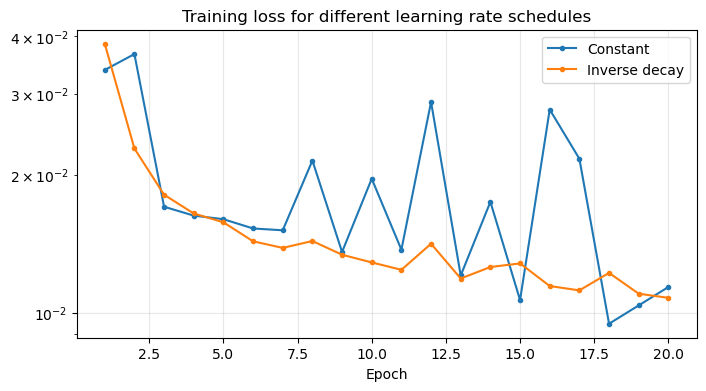

In [8]:
eta0 = 0.2
iters_per_epoch = int(np.ceil(N / 16))
schedules = {
    "Constant": eta0,
    "Inverse decay": lambda k: eta0 / (1 + k / iters_per_epoch),  # gamma = 1 / iters_per_epoch
}

plt.figure(figsize=(8, 4))
for name, lr in schedules.items():
    params = init_params([2, 64, 64, 3], seed=0)
    params, loss_hist, acc_hist, _ = train_sgd(params, X, Y, y, lr=lr, batch_size=16, epochs=20)
    print(f"{name:15s}: final loss = {loss_hist[-1]:.4f}, final accuracy = {acc_hist[-1]*100:.2f}%")
    plt.semilogy(np.arange(1, 21), loss_hist, 'o-', ms=3, label=name)
plt.xlabel("Epoch")
plt.title("Training loss for different learning rate schedules")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

With a constant (large) learning rate, the loss stops decreasing and oscillates: the iterates bounce around the minimum, as predicted by the theory. With a decaying learning rate, the noise is progressively reduced and the loss keeps decreasing.

## Remarks

- The **batch size** controls the trade-off between computational cost and gradient accuracy. Small batches introduce more stochastic noise; large batches approach full GD behavior.
- The **learning rate** and the **batch size** must be tuned together: as a rule of thumb, larger batches allow (and require) larger learning rates.
- The **number of epochs** is the natural way of measuring the computational cost of training, since it does not depend on the batch size.
- SGD is extremely sensitive to the choice of the learning rate, and it uses **the same learning rate for all the parameters**, regardless of the curvature of the loss along each direction. This makes it slow on ill-conditioned problems, which are very common in Deep Learning. In the next chapter, we will introduce **Adam**, an optimizer designed to address these issues.

> **Exercise (Batch size and time):** Repeat the comparison between GD and SGD with $N_\text{batch} \in \{1, 4, 16, 64, 256, 1024, N\}$. For each of them, measure the time required to complete one epoch and the final loss after a fixed time budget (e.g. $5$ seconds). Which batch size is the best?

> **Exercise (Learning rate):** For $N_\text{batch} = 64$, train the network with learning rates $\eta \in \{ 10^{-3}, 10^{-2}, 10^{-1}, 1 \}$. Plot the training loss for each of them and discuss the results, in light of the theory of the previous chapter.

> **Exercise (Cosine schedule):** Implement the cosine learning rate schedule, and compare it with the constant and inverse decay schedules.

> **Exercise (Generalization):** Split the spiral dataset into a training set ($80\%$) and a test set ($20\%$). Modify `train_sgd` to also record the loss and the accuracy on the test set at the end of each epoch, and plot both curves. Do you observe overfitting? What happens if you reduce the number of training datapoints to $N = 300$?